In [32]:
import math
import random
import json
from copy import deepcopy

from shapely.geometry import Polygon, box
from shapely.affinity import translate
from shapely.ops import unary_union

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

import os
import re
import numpy as np

from svgpathtools import svg2paths2
from collections import defaultdict


from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union
from shapely.geometry import box
from shapely.affinity import translate

In [55]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None
    
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)
        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: color-based grouping ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))

            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)

    # --- Case 2: fallback (no colors) ---
    else:
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)
    
    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons
    
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        
        sized_polys = assign_sizes(polygons, sizes)
        
        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })
    
    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes            

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result

def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )

def extract_polygons(shape_items):
    """
    Converts process_design_folder() output
    into pure shapely polygon list.
    """
    polys = []

    for item in shape_items:
        poly = item["polygon"]

        # Already shapely polygon → OK
        if hasattr(poly, "bounds"):
            polys.append(poly)
        else:
            # If stored as point list
            polys.append(Polygon(poly))

    return polys
    
def layout_to_kpi_items(polys):
    """
    Convert shapely polygon list into
    format expected by evaluate_kpis()
    """
    items = []

    for p in polys:
        coords = list(p.exterior.coords)
        items.append({
            "polygon": coords
        })

    return items
    
def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }


In [16]:
class MarkerMemory:
    def __init__(self):
        self.history = []
        self.best = None

    def record(self, marker_id, iteration, placed_polys, strip_width):
        height = self.compute_height(placed_polys)
        used = sum(p.area for p in placed_polys)
        total = height * strip_width
        empty_ratio = 1 - used / total if total > 0 else 0

        entry = {
            "marker_id": marker_id,
            "iteration": iteration,
            "height": height,
            "used_area": used,
            "total_area": total,
            "empty_ratio": empty_ratio
        }

        self.history.append(entry)

        if self.best is None or height < self.best["height"]:
            self.best = entry

    def compute_height(self, polys):
        if not polys:
            return 0
        return max(p.bounds[3] for p in polys)

    def summary(self):
        return {
            "runs": len(self.history),
            "best": self.best
        }

    def save(self, path="marker_memory.json"):
        with open(path, "w") as f:
            json.dump({
                "history": self.history,
                "best": self.best
            }, f, indent=2)


In [9]:
def initial_pack(shapes, strip_width):
    placed = []
    x_cursor = 0
    y_cursor = 0
    row_height = 0

    for poly in shapes:
        minx, miny, maxx, maxy = poly.bounds
        w = maxx - minx
        h = maxy - miny

        if x_cursor + w > strip_width:
            x_cursor = 0
            y_cursor += row_height
            row_height = 0

        moved = translate(poly, xoff=x_cursor - minx, yoff=y_cursor - miny)
        placed.append(moved)

        x_cursor += w
        row_height = max(row_height, h)

    return placed


In [10]:
def candidate_x_positions(placed, strip_width, poly):
    xs = {0}

    for p in placed:
        minx, _, maxx, _ = p.bounds
        xs.add(maxx)
        xs.add(minx)

    minx, _, maxx, _ = poly.bounds
    width = maxx - minx

    valid = []
    for x in xs:
        if x + width <= strip_width:
            valid.append(x)

    return sorted(valid)


In [11]:
def layout_height(polys):
    if not polys:
        return 0
    return max(p.bounds[3] for p in polys)


In [12]:
def optimize_marker_v12(polygons, strip_width, iterations=200, marker_id="M1"):
    memory = MarkerMemory()

    placed = initial_pack(polygons, strip_width)
    best_layout = deepcopy(placed)
    best_height = layout_height(placed)

    memory.record(marker_id, 0, placed, strip_width)

    no_improve = 0

    for it in range(1, iterations + 1):

        idx = random.randrange(len(placed))
        piece = placed.pop(idx)

        best_local = None
        best_local_height = float("inf")

        for x in candidate_x_positions(placed, strip_width, piece):
            test_piece = translate(piece, xoff=x - piece.bounds[0], yoff=0)

            y = 0
            while True:
                moved = translate(test_piece, yoff=y)
                collision = False

                for other in placed:
                    if moved.intersects(other):
                        collision = True
                        break

                if collision:
                    y += 0.5
                    continue
                break

            final_piece = translate(test_piece, yoff=y)
            test_layout = placed + [final_piece]
            h = layout_height(test_layout)

            if h < best_local_height:
                best_local_height = h
                best_local = final_piece

        placed.append(best_local)

        current_height = layout_height(placed)
        memory.record(marker_id, it, placed, strip_width)

        if current_height < best_height:
            best_height = current_height
            best_layout = deepcopy(placed)
            no_improve = 0
            print(f"[Iter {it}] Improved height → {round(best_height,3)}")
        else:
            no_improve += 1

        if no_improve > 40:
            print("No improvement for 40 iterations → stopping early")
            break

    print("\nBEST HEIGHT:", best_height)
    print("MEMORY SUMMARY:", memory.summary())

    memory.save(f"{marker_id}_memory.json")

    return best_layout, memory


In [74]:
def render_layout(polys, strip_width, title="Marker", save_path = None):
    fig, ax = plt.subplots(figsize=(6, 12))

    patches = []
    for p in polys:
        coords = list(p.exterior.coords)
        patches.append(MplPolygon(coords))

    pc = PatchCollection(patches, edgecolor="black", linewidth=1)
    ax.add_collection(pc)

    height = layout_height(polys)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(height, 0)
    ax.set_title(title)
    ax.set_aspect("equal")
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [76]:
# polygons must be shapely Polygon list in inches

STRIP_WIDTH = 36.0
design_folder = "JK-123"

# Load shapes (SVG-driven input)
shapes = process_design_folder(design_folder)

# convert to raw polygons
polys = extract_polygons(shapes)

best_layout, memory = optimize_marker_v12(
    polys,
    STRIP_WIDTH,
    iterations=300,
    marker_id="TEST_MARKER"
)

placed_items = layout_to_kpi_items(best_layout)

# KPIs
kpi_v12 = evaluate_kpis(placed_items, STRIP_WIDTH)

print("V12 KPIs (Envelope-Delta Free-Space):")
for k, v in kpi_v12.items():
    print(f"  {k}: {v:.3f}")
    




No improvement for 40 iterations → stopping early

BEST HEIGHT: 54.947556910322305
MEMORY SUMMARY: {'runs': 42, 'best': {'marker_id': 'TEST_MARKER', 'iteration': 0, 'height': 54.947556910322305, 'used_area': 1271.6030153499432, 'total_area': 1978.112048771603, 'empty_ratio': 0.35716330319124145}}
V12 KPIs (Envelope-Delta Free-Space):
  layer_length_in: 54.948
  used_area_in2: 1271.603
  total_area_in2: 1978.112
  empty_ratio: 0.357


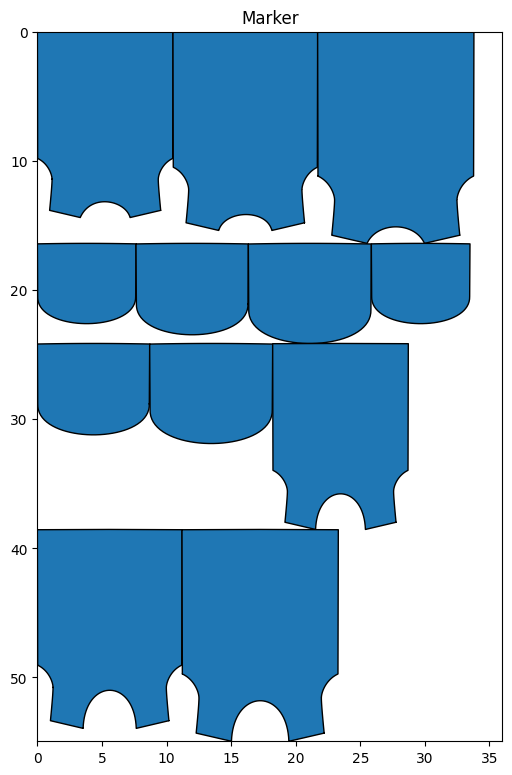

In [75]:
render_layout(best_layout, STRIP_WIDTH, save_path=f"{design_folder}/V12 Optimized.png")


In [67]:
print(polys)

[<POLYGON ((6.661e-16 0.02, 0.135 0.019, 0.269 0.019, 0.404 0.018, 0.538 0.01...>, <POLYGON ((1.332e-15 0.021, 0.144 0.021, 0.287 0.02, 0.431 0.02, 0.574 0.019...>, <POLYGON ((7.572e-16 0.023, 0.155 0.022, 0.31 0.021, 0.465 0.021, 0.621 0.02...>, <POLYGON ((7.613 4.108, 7.613 4.004, 7.614 3.9, 7.615 3.795, 7.615 3.691, 7....>, <POLYGON ((8.667 4.678, 8.668 4.559, 8.669 4.44, 8.67 4.321, 8.67 4.202, 8.6...>, <POLYGON ((9.492 5.122, 9.492 4.992, 9.493 4.862, 9.494 4.732, 9.495 4.602, ...>, <POLYGON ((7.613 4.108, 7.613 4.004, 7.614 3.9, 7.615 3.795, 7.615 3.691, 7....>, <POLYGON ((8.667 4.678, 8.668 4.559, 8.669 4.44, 8.67 4.321, 8.67 4.202, 8.6...>, <POLYGON ((9.492 5.122, 9.492 4.992, 9.493 4.862, 9.494 4.732, 9.495 4.602, ...>, <POLYGON ((1.665e-15 0.02, 0.135 0.019, 0.269 0.019, 0.404 0.018, 0.538 0.01...>, <POLYGON ((8.327e-16 0.021, 0.144 0.021, 0.287 0.02, 0.431 0.02, 0.574 0.019...>, <POLYGON ((1.62e-15 0.023, 0.155 0.022, 0.31 0.021, 0.465 0.021, 0.621 0.02,...>]
